*Updated 18 November 2026. I rebuilt this post on month-by-month counts from GitHub's Search API. The first version said public activity grew steadily through 2025. It didn't: it took off. The source I used then was seeing a shrinking share of public activity, as [explained below](#why-the-public-event-log-missed-it).*

I wanted to know how much AI has changed the way code gets written. GitHub is the closest thing we have to a public record of software, so I collected GitHub's own numbers from 2008 to 2026, counted public pull requests and repositories month by month with GitHub's Search API from January 2022 to October 2026, used the GH Archive event log for the longer history, and read the studies on AI and code quality. Here is what the numbers show, and where they stop.

## In short

- **The jump is real, and it landed in 2026.** Public pull requests merged per month went from 3.4 million in 2024 and 4.7 million in 2025 to 12.6 million so far in 2026, and 26.3 million in October 2026 alone. Across public and private repositories, GitHub counted 34.3 billion commits and 1.3 billion merged pull requests in the year to September 2026, both more than three times the level of two years earlier.
- **Growth was slowing before agents.** Public merged pull requests grew 20% in 2023 and 10% in 2024, then 39% in 2025 and 178% in the first ten months of 2026.
- **People didn't triple; output did.** Developers grew about 1.5 times over two years, so each developer ships about twice as much.
- **Agents arrived in mid-2025 and took off in 2026.** The share of new public pull requests carrying an AI tool's signature went from about 0.1% in April 2025 to 8% in October 2025 and 28% in October 2026. Claude Code's footer alone was on 22%.
- **Changes got bigger.** The median merged public pull request added 22–23 lines from 2022 to 2024, 30 in 2025, and 35 in the last weeks of full data.
- **More code is not the same as better code.** Studies find more copy/paste, much less refactoring, and mixed effects on speed and stability.
- **Some of the surge may be noise.** Search counts what is on GitHub today, including spam GitHub hasn't removed yet, and the newest months have had the least time to be cleaned up. How much of 2026 that explains is unknown.

## The numbers now

<div class="stats"><div><b>26.3M</b><span>public pull requests merged in October 2026, 4.6× a year earlier</span></div><div><b>28%</b><span>of new public pull requests carry an AI tool's signature, October 2026</span></div><div><b>34.3B</b><span>commits in the year to September 2026, public and private</span></div><div><b>1.3B</b><span>pull requests merged in the same year</span></div></div>

Sources: my counts from GitHub's Search API (method below), [GitHub Octoverse 2026](https://github.blog/news-insights/octoverse/octoverse-commits-pushes-reach-new-highs-in-2026-as-developers-build-with-agents/) and [Octoverse 2025](https://github.blog/news-insights/octoverse/octoverse-a-new-developer-joins-github-every-second-as-ai-leads-typescript-to-1/). GitHub also reports more than 225 million developers, and says agents started more than 40% of all pull requests by September 2026.

In [1]:
import sys
sys.path.insert(0, 'github-after-ai')
import figures
from IPython.display import SVG, display

## Eighteen years of growth

Start with the long view. GitHub's growth in people didn't speed up in the AI era: developers doubled about every year and a half from 2012 to 2017, and every two and a half to three years since.

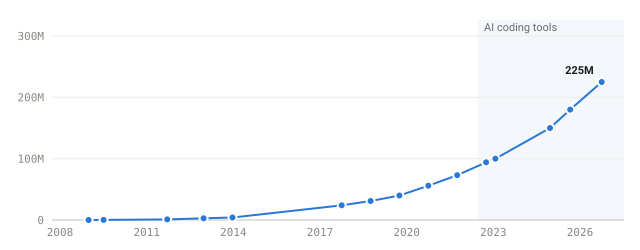

In [2]:
display(SVG(figures.developers_chart()))

<details><summary>Data table</summary><table><thead><tr><th>As of</th><th>Developers</th></tr></thead><tbody><tr><td>end of 2008</td><td>40K</td></tr><tr><td>Jul 2009</td><td>100K</td></tr><tr><td>Sep 2011</td><td>1M</td></tr><tr><td>Dec 2012</td><td>2.8M</td></tr><tr><td>Dec 2013</td><td>4M</td></tr><tr><td>2017</td><td>24M</td></tr><tr><td>2018</td><td>31M</td></tr><tr><td>2019</td><td>40M</td></tr><tr><td>2020</td><td>56M</td></tr><tr><td>2021</td><td>73M</td></tr><tr><td>2022</td><td>94M</td></tr><tr><td>Jan 2023</td><td>100M</td></tr><tr><td>Dec 2024</td><td>150M</td></tr><tr><td>Aug 2025</td><td>180M</td></tr><tr><td>Sep 2026</td><td>225M</td></tr></tbody></table></details>

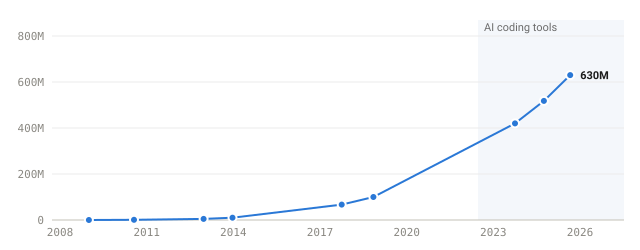

In [3]:
display(SVG(figures.repositories_chart()))

<details><summary>Data table</summary><table><thead><tr><th>As of</th><th>Repositories</th></tr></thead><tbody><tr><td>Jan 2009, public only</td><td>50K</td></tr><tr><td>Jul 2010</td><td>1M</td></tr><tr><td>Dec 2012</td><td>4.6M</td></tr><tr><td>Dec 2013</td><td>10M</td></tr><tr><td>2017</td><td>67M</td></tr><tr><td>Nov 2018</td><td>100M</td></tr><tr><td>2023</td><td>420M</td></tr><tr><td>2024</td><td>518M</td></tr><tr><td>Aug 2025</td><td>630M</td></tr></tbody></table></details>

GitHub has changed what it counts over the years (public only, all repositories, with or without forks), so read these as the numbers GitHub reported at the time.

Public activity grew quickly for most of the decade, then slowed just before agents arrived. In [GH Archive](https://www.gharchive.org/), the public log of GitHub events, public commits grew about 27% a year from 2015 to 2022, and merged pull requests about 35% a year. In 2023 and 2024, merged pull requests grew only 16% and 8% in GH Archive, and 20% and 10% in GitHub's Search API.

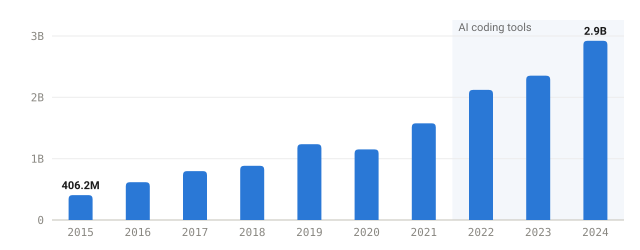

In [4]:
display(SVG(figures.commits_chart()))

<details><summary>Data table</summary><table><thead><tr><th>Year</th><th>Public commits (at most 1,000 per push)</th><th>Merged PRs (GH Archive)</th><th>Merged PRs (Search API)</th></tr></thead><tbody><tr><td>2015</td><td>406.2M</td><td>4M</td><td></td></tr><tr><td>2016</td><td>616.6M</td><td>8M</td><td></td></tr><tr><td>2017</td><td>797M</td><td>11.4M</td><td></td></tr><tr><td>2018</td><td>884.1M</td><td>13M</td><td></td></tr><tr><td>2019</td><td>1.2B</td><td>19.1M</td><td></td></tr><tr><td>2020</td><td>1.2B</td><td>23.7M</td><td></td></tr><tr><td>2021</td><td>1.6B</td><td>32.9M</td><td></td></tr><tr><td>2022</td><td>2.1B</td><td>33.2M</td><td>31.2M</td></tr><tr><td>2023</td><td>2.4B</td><td>38.5M</td><td>37.4M</td></tr><tr><td>2024</td><td>2.9B</td><td>41.5M</td><td>41M</td></tr></tbody></table></details>

The commit counts include at most 1,000 commits per push. Until June 2023 GitHub's event log itself reported at most 1,000 per push; then it raised that cap to 10,000, so counting every commit would make the later years look far bigger than they are. The chart stops at 2024: GH Archive's 2025 estimate rests on three sampled hours, and it counts only about 73% of the merged pull requests that Search finds for that year (more on that below).

## 2026 is the jump

Then it took off. GitHub's Search API counts public pull requests merged in any month, and the curve bends upward soon after coding agents became widely available in May 2025.

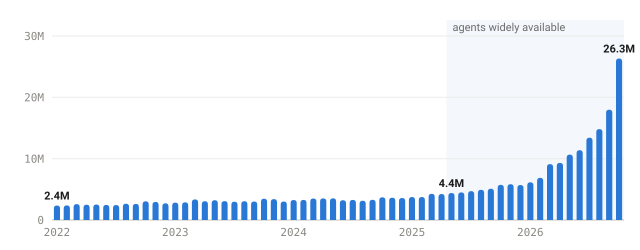

In [5]:
display(SVG(figures.merged_monthly_chart()))

<details><summary>Data table</summary><table><thead><tr><th>Month</th><th>Public PRs merged</th></tr></thead><tbody><tr><td>Jan 2022</td><td>2,366,248</td></tr><tr><td>Feb 2022</td><td>2,372,413</td></tr><tr><td>Mar 2022</td><td>2,588,228</td></tr><tr><td>Apr 2022</td><td>2,489,703</td></tr><tr><td>May 2022</td><td>2,525,854</td></tr><tr><td>Jun 2022</td><td>2,460,981</td></tr><tr><td>Jul 2022</td><td>2,439,708</td></tr><tr><td>Aug 2022</td><td>2,655,186</td></tr><tr><td>Sep 2022</td><td>2,618,803</td></tr><tr><td>Oct 2022</td><td>3,049,705</td></tr><tr><td>Nov 2022</td><td>2,943,127</td></tr><tr><td>Dec 2022</td><td>2,718,359</td></tr><tr><td>Jan 2023</td><td>2,840,979</td></tr><tr><td>Feb 2023</td><td>2,882,997</td></tr><tr><td>Mar 2023</td><td>3,365,136</td></tr><tr><td>Apr 2023</td><td>3,060,414</td></tr><tr><td>May 2023</td><td>3,228,968</td></tr><tr><td>Jun 2023</td><td>3,085,940</td></tr><tr><td>Jul 2023</td><td>2,986,946</td></tr><tr><td>Aug 2023</td><td>3,057,339</td></tr><tr><td>Sep 2023</td><td>3,018,032</td></tr><tr><td>Oct 2023</td><td>3,470,955</td></tr><tr><td>Nov 2023</td><td>3,409,043</td></tr><tr><td>Dec 2023</td><td>3,018,646</td></tr><tr><td>Jan 2024</td><td>3,268,957</td></tr><tr><td>Feb 2024</td><td>3,272,087</td></tr><tr><td>Mar 2024</td><td>3,511,163</td></tr><tr><td>Apr 2024</td><td>3,526,020</td></tr><tr><td>May 2024</td><td>3,532,520</td></tr><tr><td>Jun 2024</td><td>3,234,416</td></tr><tr><td>Jul 2024</td><td>3,281,985</td></tr><tr><td>Aug 2024</td><td>3,144,317</td></tr><tr><td>Sep 2024</td><td>3,300,979</td></tr><tr><td>Oct 2024</td><td>3,707,833</td></tr><tr><td>Nov 2024</td><td>3,642,639</td></tr><tr><td>Dec 2024</td><td>3,582,191</td></tr><tr><td>Jan 2025</td><td>3,748,766</td></tr><tr><td>Feb 2025</td><td>3,745,029</td></tr><tr><td>Mar 2025</td><td>4,279,271</td></tr><tr><td>Apr 2025</td><td>4,237,714</td></tr><tr><td>May 2025</td><td>4,404,334</td></tr><tr><td>Jun 2025</td><td>4,507,061</td></tr><tr><td>Jul 2025</td><td>4,709,894</td></tr><tr><td>Aug 2025</td><td>4,919,055</td></tr><tr><td>Sep 2025</td><td>5,095,991</td></tr><tr><td>Oct 2025</td><td>5,741,985</td></tr><tr><td>Nov 2025</td><td>5,833,015</td></tr><tr><td>Dec 2025</td><td>5,709,185</td></tr><tr><td>Jan 2026</td><td>6,149,176</td></tr><tr><td>Feb 2026</td><td>6,872,778</td></tr><tr><td>Mar 2026</td><td>9,118,212</td></tr><tr><td>Apr 2026</td><td>9,313,369</td></tr><tr><td>May 2026</td><td>10,665,404</td></tr><tr><td>Jun 2026</td><td>11,383,763</td></tr><tr><td>Jul 2026</td><td>13,424,214</td></tr><tr><td>Aug 2026</td><td>14,826,325</td></tr><tr><td>Sep 2026</td><td>17,991,400</td></tr><tr><td>Oct 2026</td><td>26,325,337</td></tr></tbody></table></details>

<table><thead><tr><th>Year</th><th>Public PRs merged per month</th><th>Change</th></tr></thead><tbody><tr><td>2022</td><td>2.60M</td><td></td></tr><tr><td>2023</td><td>3.12M</td><td>+20%</td></tr><tr><td>2024</td><td>3.42M</td><td>+10%</td></tr><tr><td>2025</td><td>4.74M</td><td>+39%</td></tr><tr><td>2026 (Jan to Oct)</td><td>12.61M</td><td>+178% vs same months</td></tr></tbody></table>

Public merged pull requests grew 39% in 2025. In the first ten months of 2026 there were 2.8 times as many as in the same months of 2025, and the pace kept rising within the year: 6.1 million in January, 9.3 million in April, 13.4 million in July and 26.3 million in October. New public repositories show the same shape, a bit milder: up 35% in 2025 and 72% in 2026 so far.

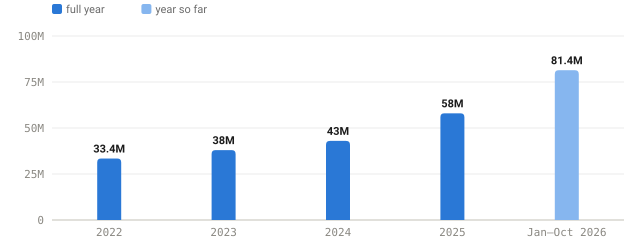

In [6]:
display(SVG(figures.new_repos_chart()))

<details><summary>Data table</summary><table><thead><tr><th>Year</th><th>New public repositories</th><th>Change</th></tr></thead><tbody><tr><td>2022</td><td>33,414,598</td><td></td></tr><tr><td>2023</td><td>37,982,617</td><td>+14%</td></tr><tr><td>2024</td><td>43,007,824</td><td>+13%</td></tr><tr><td>2025</td><td>58,012,884</td><td>+35%</td></tr><tr><td>2026 (Jan to Oct)</td><td>81,404,844</td><td>+72% vs same months</td></tr></tbody></table></details>

GitHub's own count of public contributions agrees: 1.12 billion in 2025 and 2.5 billion in 2026 ([Octoverse 2026](https://github.blog/news-insights/octoverse/octoverse-commits-pushes-reach-new-highs-in-2026-as-developers-build-with-agents/)). Across public and private repositories, commits and merged pull requests both more than tripled in two years. Public merged pull requests grew about as much over the same two years (October to September): 2.9 times.

## Agents arrived in mid-2025, and took off in 2026

Coding agents leave fingerprints on the pull requests they open. For every month I counted new public pull requests with any of these:

- opened by an agent's own account (the Copilot coding agent, Google Jules, Devin);
- carrying a tool's default footer or link in the description (Claude Code and Cursor; Codex until November 2025);
- for Codex, on a branch named the way it names them (`codex/`), since Codex stopped adding its link in November 2025. Each month uses whichever Codex count is larger.

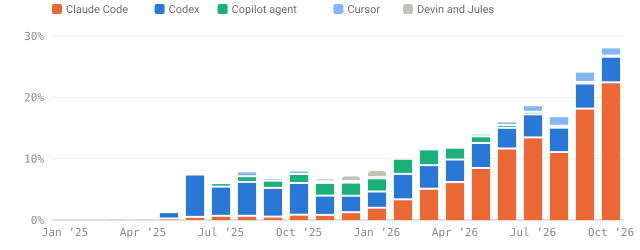

In [7]:
display(SVG(figures.agent_share_chart()))

<details><summary>Data table</summary><table><thead><tr><th>Month</th><th>New public PRs</th><th>Claude Code</th><th>Codex</th><th>Copilot agent</th><th>Cursor</th><th>Devin and Jules</th><th>All signals</th></tr></thead><tbody><tr><td>Jan 2025</td><td>4,798,412</td><td>&lt;0.001%</td><td>&lt;0.001%</td><td>0%</td><td>0%</td><td>0.049%</td><td>0.0494%</td></tr><tr><td>Feb 2025</td><td>4,963,400</td><td>0.00459%</td><td>0%</td><td>0%</td><td>&lt;0.001%</td><td>0.0576%</td><td>0.0622%</td></tr><tr><td>Mar 2025</td><td>5,671,565</td><td>0.0195%</td><td>0%</td><td>&lt;0.001%</td><td>0%</td><td>0.0562%</td><td>0.076%</td></tr><tr><td>Apr 2025</td><td>5,505,440</td><td>0.0219%</td><td>&lt;0.001%</td><td>&lt;0.001%</td><td>0%</td><td>0.0883%</td><td>0.111%</td></tr><tr><td>May 2025</td><td>5,698,831</td><td>0.0801%</td><td>1.04%</td><td>0.0882%</td><td>0%</td><td>0.092%</td><td>1.3%</td></tr><tr><td>Jun 2025</td><td>6,256,033</td><td>0.347%</td><td>6.91%</td><td>0.214%</td><td>&lt;0.001%</td><td>0.0659%</td><td>7.54%</td></tr><tr><td>Jul 2025</td><td>6,526,212</td><td>0.518%</td><td>4.76%</td><td>0.569%</td><td>0.0873%</td><td>0.0889%</td><td>6.02%</td></tr><tr><td>Aug 2025</td><td>6,906,705</td><td>0.527%</td><td>5.52%</td><td>0.927%</td><td>0.791%</td><td>0.258%</td><td>8.03%</td></tr><tr><td>Sep 2025</td><td>7,561,946</td><td>0.397%</td><td>4.68%</td><td>1.19%</td><td>0.425%</td><td>0.208%</td><td>6.9%</td></tr><tr><td>Oct 2025</td><td>8,198,076</td><td>0.701%</td><td>5.17%</td><td>1.46%</td><td>0.578%</td><td>0.242%</td><td>8.15%</td></tr><tr><td>Nov 2025</td><td>8,227,536</td><td>0.677%</td><td>3.14%</td><td>2.07%</td><td>0.247%</td><td>0.494%</td><td>6.63%</td></tr><tr><td>Dec 2025</td><td>8,160,013</td><td>1.11%</td><td>2.69%</td><td>2.15%</td><td>0.231%</td><td>0.931%</td><td>7.1%</td></tr><tr><td>Jan 2026</td><td>8,873,855</td><td>1.84%</td><td>2.65%</td><td>2.15%</td><td>0.16%</td><td>1.2%</td><td>8%</td></tr><tr><td>Feb 2026</td><td>9,934,338</td><td>3.2%</td><td>4.16%</td><td>2.46%</td><td>0.155%</td><td>0.126%</td><td>10.1%</td></tr><tr><td>Mar 2026</td><td>12,235,044</td><td>4.93%</td><td>3.86%</td><td>2.57%</td><td>0.197%</td><td>0.153%</td><td>11.7%</td></tr><tr><td>Apr 2026</td><td>12,319,678</td><td>6.02%</td><td>3.67%</td><td>1.93%</td><td>0.267%</td><td>0.267%</td><td>12.2%</td></tr><tr><td>May 2026</td><td>13,816,505</td><td>8.32%</td><td>4.07%</td><td>1.09%</td><td>0.425%</td><td>0.322%</td><td>14.2%</td></tr><tr><td>Jun 2026</td><td>14,840,207</td><td>11.5%</td><td>3.37%</td><td>0.449%</td><td>0.587%</td><td>0.284%</td><td>16.2%</td></tr><tr><td>Jul 2026</td><td>17,056,961</td><td>13.3%</td><td>3.77%</td><td>0.393%</td><td>1.08%</td><td>0.233%</td><td>18.8%</td></tr><tr><td>Aug 2026</td><td>18,694,242</td><td>10.9%</td><td>3.98%</td><td>0.327%</td><td>1.54%</td><td>0.232%</td><td>17%</td></tr><tr><td>Sep 2026</td><td>22,450,805</td><td>18%</td><td>4.1%</td><td>0.263%</td><td>1.66%</td><td>0.222%</td><td>24.2%</td></tr><tr><td>Oct 2026</td><td>32,408,250</td><td>22.3%</td><td>4.18%</td><td>0.186%</td><td>1.33%</td><td>0.197%</td><td>28.2%</td></tr></tbody></table></details>

The signal stayed around 0.1% of new public pull requests until April 2025. Codex, the Copilot coding agent, Jules and Claude Code all became widely available in May, and by June 7.5% of new public pull requests carried a signal. It stayed between 6 and 10% until February 2026, then rose from 12% in March to 28% in October 2026, most of it from Claude Code. GH Archive, an independent record, shows the same start: under 0.3% in every month until May 2025, then 5 to 11% in sampled hours from June.

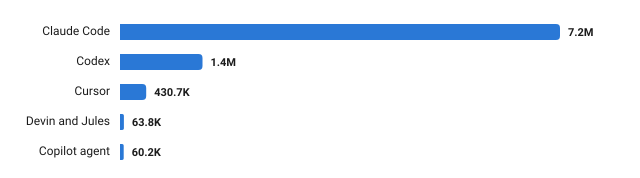

In [8]:
display(SVG(figures.agent_tools_chart()))

<details><summary>Data table</summary><table><thead><tr><th>Tool</th><th>Public PRs opened, Oct 2026</th><th>Share of all new PRs</th></tr></thead><tbody><tr><td>Claude Code</td><td>7,223,970</td><td>22.3%</td></tr><tr><td>Codex</td><td>1,354,019</td><td>4.18%</td></tr><tr><td>Cursor</td><td>430,747</td><td>1.33%</td></tr><tr><td>Devin and Jules</td><td>63,843</td><td>0.197%</td></tr><tr><td>Copilot agent</td><td>60,236</td><td>0.186%</td></tr></tbody></table></details>

In October 2026 alone, 7.2 million new public pull requests carried Claude Code's footer, 22% of all of them. `codex/` branches were on 1.35 million (4%), and Cursor's agent links on 431,000 (1.3%). The Copilot coding agent's signal peaked at 314,000 in March 2026 and fell to 60,000 in October; Devin opened 52,000 and Jules 11,000.

Read these as rough. They miss AI help that leaves no trace, such as an assistant inside an editor or a footer someone deleted. They can also count a pull request twice if it carries two signals, and a branch name is only a name, so `codex/` can catch branches people named by hand. Across public and private repositories, [GitHub says](https://github.blog/news-insights/octoverse/octoverse-commits-pushes-reach-new-highs-in-2026-as-developers-build-with-agents/) agents started more than 40% of pull requests by September 2026. The public signal I can count was 24% that month.

## Changes got bigger

Lines of code is the number I most wanted, and nobody publishes it. The closest public measure is the size of merged pull requests, which GH Archive recorded until October 2025. The typical merged pull request added 22 or 23 lines from 2022 to 2024. In 2025 it added 30 (from three sampled hours, about 17,000 merged pull requests), and in the last two weeks of full data (25 September to 8 October 2025) the median was 35.

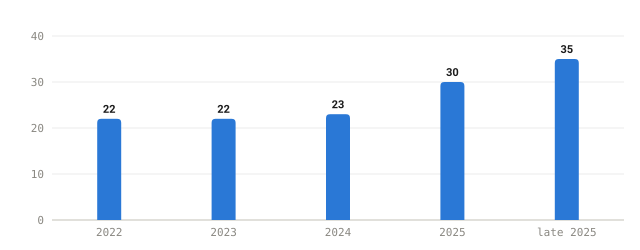

In [9]:
display(SVG(figures.pr_size_zoom_chart()))

<details><summary>Data table</summary><table><thead><tr><th>Year</th><th>Median lines added per merged public PR</th></tr></thead><tbody><tr><td>2015</td><td>21</td></tr><tr><td>2016</td><td>18</td></tr><tr><td>2017</td><td>24</td></tr><tr><td>2018</td><td>23</td></tr><tr><td>2019</td><td>25</td></tr><tr><td>2020</td><td>26</td></tr><tr><td>2021</td><td>24</td></tr><tr><td>2022</td><td>22</td></tr><tr><td>2023</td><td>22</td></tr><tr><td>2024</td><td>23</td></tr><tr><td>2025</td><td>30</td></tr><tr><td>25 Sep to 8 Oct 2025</td><td>35</td></tr></tbody></table></details>

That fits how agents work: [GitHub found](https://github.blog/news-insights/octoverse/octoverse-commits-pushes-reach-new-highs-in-2026-as-developers-build-with-agents/) that agent-started pull requests change several files 87% of the time, against 79% for the rest. For ten years before that, from 2015 to 2024, the median never left the 18–26 line range. I can't extend this into 2026. GitHub stopped publishing pull request sizes in October 2025, and the sizes I sampled through the API failed a check against known values (93 lines for a month where the full data says 21 to 23), so I left them out.

## Why the public event log missed it

The first version of this post was built on [GH Archive](https://www.gharchive.org/), and it said public growth stayed steady through 2025. The log was seeing a shrinking share of public activity. Until mid-2024, its monthly count of merged pull requests matched GitHub's Search API closely: the ratio between the two had a median of 0.98 over 16 months. GH Archive's 2025 sample, taken in February, May and August, estimated only about 73% of the merged pull requests Search finds for that year (41.8 million against 56.9 million), so it showed 2025 as flat when it grew 39%. After GitHub [trimmed its public event stream](https://github.blog/changelog/2025-08-08-upcoming-changes-to-github-events-api-payloads/) on 7 October 2025, GH Archive recorded only 29 to 39% of the pull requests that Search counts.

<details><summary>Data table</summary><table><thead><tr><th>Month</th><th>Public PRs</th><th>GH Archive</th><th>Search API</th><th>GH Archive ÷ Search</th></tr></thead><tbody><tr><td>Feb 2023</td><td>merged</td><td>2,960,560</td><td>2,882,997</td><td>1.03</td></tr><tr><td>Mar 2023</td><td>merged</td><td>3,186,530</td><td>3,365,136</td><td>0.95</td></tr><tr><td>Apr 2023</td><td>merged</td><td>2,945,230</td><td>3,060,414</td><td>0.96</td></tr><tr><td>May 2023</td><td>merged</td><td>3,071,279</td><td>3,228,968</td><td>0.95</td></tr><tr><td>Jun 2023</td><td>merged</td><td>2,966,567</td><td>3,085,940</td><td>0.96</td></tr><tr><td>Jul 2023</td><td>merged</td><td>3,003,134</td><td>2,986,946</td><td>1.01</td></tr><tr><td>Aug 2023</td><td>merged</td><td>3,021,809</td><td>3,057,339</td><td>0.99</td></tr><tr><td>Sep 2023</td><td>merged</td><td>3,058,447</td><td>3,018,032</td><td>1.01</td></tr><tr><td>Oct 2023</td><td>merged</td><td>3,475,226</td><td>3,470,955</td><td>1.00</td></tr><tr><td>Nov 2023</td><td>merged</td><td>3,314,120</td><td>3,409,043</td><td>0.97</td></tr><tr><td>Dec 2023</td><td>merged</td><td>2,832,016</td><td>3,018,646</td><td>0.94</td></tr><tr><td>Jan 2024</td><td>merged</td><td>3,282,337</td><td>3,268,957</td><td>1.00</td></tr><tr><td>Feb 2024</td><td>merged</td><td>3,198,612</td><td>3,272,087</td><td>0.98</td></tr><tr><td>Mar 2024</td><td>merged</td><td>3,459,255</td><td>3,511,163</td><td>0.99</td></tr><tr><td>Apr 2024</td><td>merged</td><td>3,436,171</td><td>3,526,020</td><td>0.97</td></tr><tr><td>May 2024</td><td>merged</td><td>3,459,106</td><td>3,532,520</td><td>0.98</td></tr><tr><td>Nov 2025</td><td>opened</td><td>3,147,865</td><td>8,227,536</td><td>0.38</td></tr><tr><td>Dec 2025</td><td>opened</td><td>3,176,586</td><td>8,160,013</td><td>0.39</td></tr><tr><td>Jan 2026</td><td>opened</td><td>3,182,595</td><td>8,873,855</td><td>0.36</td></tr><tr><td>Feb 2026</td><td>opened</td><td>2,930,569</td><td>9,934,338</td><td>0.29</td></tr></tbody></table></details>

I can't tell exactly why. Google's open source team [estimates](https://opensource.googleblog.com/2026/09/how-much-should-you-trust-your-oss-data.html) that GH Archive now captures about half of all events, and as little as 20% for some types. The free ClickHouse mirror of GH Archive I used also has no data from June 2024 to late September 2025, which include the months when agents arrived. The lesson for me: check one source against another before trusting a trend, especially a flat one.

## More code, same quality?

- **Code quality.** [GitClear](https://www.gitclear.com/ai_assistant_code_quality_2025_research) (211 million changed lines, 2020–2024): refactored, "moved" code fell from 25% of changed lines in 2021 to under 10% in 2024, while copy/pasted lines rose from 8.3% to 12.3%. Its [2026 report](https://www.gitclear.com/the_ai_code_quality_maintainability_gap) puts moved code at 3.8% and copy/paste at 15.7% in the first half of 2026.
- **Speed.** In [METR's 2025 trial](https://metr.org/blog/2025-07-10-early-2025-ai-experienced-os-dev-study/), 16 experienced open-source developers worked on 246 real tasks, each randomly allowed or barred from AI tools. With AI allowed they took 19% longer, while believing they were 20% faster. A [2026 follow-up](https://metr.org/blog/2026-02-24-uplift-update/) could not get a clean answer, partly because developers no longer want to work without AI.
- **Delivery.** In [DORA 2024](https://services.google.com/fh/files/misc/2024_final_dora_report.pdf), more AI adoption came with slightly lower throughput and lower stability. In [DORA 2025](https://services.google.com/fh/files/misc/2025_state_of_ai_assisted_software_development.pdf), throughput improved, but instability still rose.
- **Trust.** In the [Stack Overflow survey](https://survey.stackoverflow.co/2025/ai), the share of developers using or planning to use AI tools went from 70% in 2023 to 84% in 2025, while 46% distrusted the accuracy of AI tools and 33% trusted it.
- **Inside companies.** Google said more than a quarter of its new code was AI-generated in [October 2024](https://blog.google/inside-google/message-ceo/alphabet-earnings-q3-2024/), and 75% in [April 2026](https://blog.google/innovation-and-ai/infrastructure-and-cloud/google-cloud/cloud-next-2026-sundar-pichai/). Microsoft said 20–30% in [April 2025](https://www.cnbc.com/2025/04/29/satya-nadella-says-as-much-as-30percent-of-microsoft-code-is-written-by-ai.html).

## What we can't measure

- **Lines of code.** GitHub reports pushes, commits, pull requests and contributions, never lines. The closest large count is [Software Heritage](https://www.softwareheritage.org/2026/01/21/software-heritage-archive-digital-public-good/)'s 27 billion unique source files across all code hosts, and that counts files, not lines.
- **How much of the 2026 surge is real.** Search counts what is on GitHub today: deleted pull requests, spam GitHub has removed and private repositories are left out. Spam that GitHub hasn't caught yet is still in, and recent months have had the least time to be cleaned up, so late 2026 may be overstated by an amount I can't measure. Opened pull requests are noisier still (spam waves in February and December 2022), which is why the volume charts use merged ones.
- **Private code.** Most work happens in private repositories (81.5% of contributions in 2025, per [Octoverse 2025](https://github.blog/news-insights/octoverse/octoverse-a-new-developer-joins-github-every-second-as-ai-leads-typescript-to-1/)), and public data can't see them.
- **Commits and sizes after October 2025.** GitHub [removed commit counts, pull request sizes and descriptions](https://github.blog/changelog/2025-08-08-upcoming-changes-to-github-events-api-payloads/) from its public event stream on 7 October 2025, so there is no public count of commits or lines changed for 2026.
- **Comparisons across GitHub reports.** Octoverse 2025 counted public activity only, and Octoverse 2026 counts public and private repositories, so their totals can't be compared directly.

## Reproduce it

Everything here comes from public data. The [analysis notebook, data, queries and scripts](https://github.com/arunima811/arunima811.github.io/tree/main/notebooks/github-after-ai) are in this site's repository.

- **January 2022 to October 2026, monthly (the main numbers):** GitHub's Search API. Each number is the total count of one search, such as `is:pr is:merged merged:2026-10-01..2026-10-31`, or `is:pr created:2026-10-01..2026-10-31 "Generated with Claude Code" in:body` for a tool's signature. All 761 counts came back complete. `scripts/ghpull.py` reruns them, and `data/api/` has the results, every query and the checks.
- **2023 to mid-2026, exact counts:** the GH Archive mirror on the free [ClickHouse playground](https://play.clickhouse.com/) (table `github_events`). `queries.sql` holds the final queries.
- **2015 to 2025, yearly estimates:** four sampled hours per year (three for 2025) from the raw GH Archive files (`scripts/sample_gharchive.py`), scaled to a year with weekday and weekend factors. On full 2023 data this lands within 1 to 9% of the exact totals.
- **Archive-gap months for the agent start:** two sampled hours per month (`scripts/sample_signatures.py`).

The quickest check needs only the [GitHub CLI](https://cli.github.com/):

```sh
gh api -X GET search/issues -f q='is:pr is:merged merged:2026-10-01..2026-10-31' -f per_page=1 --jq .total_count
```

On 18 November 2026 this returned 26,270,556, 0.2% below my count two to three days earlier. Expect it to keep drifting down a little as GitHub removes spam.

This snippet rebuilds the monthly counts of new pull requests on agent branches from GH Archive on the playground (a few seconds):

In [ ]:
import urllib.request

SQL = """
SELECT
    toStartOfMonth(created_at) AS month,
    count() AS prs_opened,
    countIf(startsWith(lower(head_ref), 'claude/')) AS branch_claude,
    countIf(startsWith(lower(head_ref), 'codex/')) AS branch_codex,
    countIf(startsWith(lower(head_ref), 'copilot/')) AS branch_copilot,
    countIf(startsWith(lower(head_ref), 'cursor/')) AS branch_cursor,
    countIf(startsWith(lower(head_ref), 'devin/')) AS branch_devin,
    countIf(multiSearchAny(lower(head_ref), ['claude/', 'codex/', 'copilot/', 'cursor/', 'devin/']) AND match(lower(head_ref), '^(claude|codex|copilot|cursor|devin)/')) AS branch_any_agent_prefix
FROM github_events
WHERE event_type = 'PullRequestEvent' AND action = 'opened'
  AND created_at >= '2023-02-01 00:00:00' AND created_at < '2026-07-01 00:00:00'
GROUP BY month
ORDER BY month FORMAT CSVWithNames;
"""
req = urllib.request.Request("https://play.clickhouse.com/?user=play", data=SQL.strip().rstrip(";").encode())
print(urllib.request.urlopen(req, timeout=120).read().decode())

GitHub's own numbers (developers, repositories, the 2026 totals) come from GitHub's blog and Octoverse reports, linked above. GitHub has changed its definitions several times, so treat cross-year comparisons of those as approximate.